# 02 · Predicting points: baselines vs. machine learning

Goal: predict each player's FPL points for an upcoming fixture.
Every feature uses only matches **before** the fixture (no data leakage), and evaluation is **time-based**: train on earlier seasons, test on later ones.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from fpl_ml import data, features, plots
plots.use_style()
FIG = Path("../reports/figures")
from fpl_ml import metrics, models, train
df = train.load_features()
print(f"{len(df):,} rows, {len(features.FEATURES)} features")
features.FEATURES

119,822 rows, 33 features


['minutes_last3',
 'total_points_last3',
 'xg_last3',
 'xa_last3',
 'bonus_last3',
 'bps_last3',
 'saves_last3',
 'starts_last3',
 'minutes_last5',
 'total_points_last5',
 'xg_last5',
 'xa_last5',
 'bonus_last5',
 'bps_last5',
 'saves_last5',
 'starts_last5',
 'played60_rate_last5',
 'matches_before',
 'season_points_per_match',
 'season_minutes_per_match',
 'season_xg_per90',
 'season_xa_per90',
 'value',
 'was_home',
 'team_xg_for',
 'team_xg_against',
 'team_goals_for',
 'team_goals_against',
 'opp_xg_for',
 'opp_xg_against',
 'opp_goals_for',
 'opp_goals_against',
 'position']

## 1. The models
| Model | Idea |
|---|---|
| Last-5 average | baseline: a player scores what he averaged over his last 5 matches |
| FPL official xP | FPL's own estimate as recorded in the dataset (reference only, see note in the results) |
| Ridge regression | linear model on standardised features, missing values imputed |
| LightGBM | gradient-boosted decision trees; handles missing values and non-linear effects |

## 2. Validation: train 2022-25, test 2025-26

In [2]:
train_val = df[df.season.isin(train.TRAIN_SEASONS)]
validation = df[df.season == train.VALIDATION_SEASON]
val_results, val_pred = train.evaluate(train_val, validation)
pd.DataFrame(val_results).T.rename(index=train.MODEL_LABELS)[["mae", "rank_corr", "top10_points", "captain_points"]]

,mae,rank_corr,top10_points,captain_points
Last-5 average (baseline),2.237,0.271,4.121,4.711
FPL official xP*,2.671,0.582,3.689,5.816
Ridge regression,1.990,0.341,4.724,7.289
LightGBM,1.994,0.339,4.871,7.132


Both ML models beat the baseline on every measure. Ridge and LightGBM are very close on average error: FPL points are so noisy that most of the remaining error cannot be predicted from pre-match information (see section 5).

Average error per gameweek through the validation season:

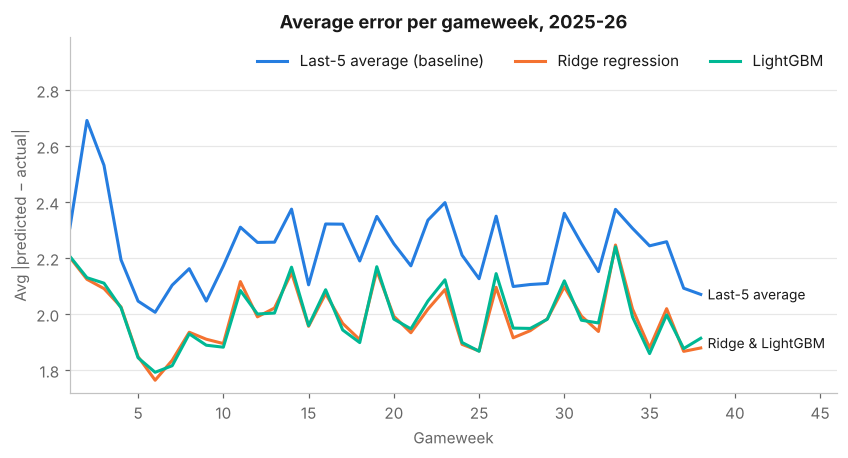

In [3]:
scores = {k: metrics.gameweek_scores(val_pred, k).set_index("gw")["mae"] for k in ["last5", "ridge", "lgbm"]}
fig, ax = plt.subplots(figsize=(9, 4.2))
for i, k in enumerate(["last5", "ridge", "lgbm"]):
    s = scores[k]
    ax.plot(s.index, s.values, color=plots.SERIES[i], label=train.MODEL_LABELS[k])
# end labels: the baseline on its own, the two ML models together (their lines finish almost on top of each other)
ax.annotate("Last-5 average", (scores["last5"].index[-1] + 0.4, scores["last5"].values[-1]), fontsize=9, color=plots.TEXT, va="center")
ml_end = (scores["ridge"].values[-1] + scores["lgbm"].values[-1]) / 2
ax.annotate("Ridge & LightGBM", (scores["lgbm"].index[-1] + 0.4, ml_end), fontsize=9, color=plots.TEXT, va="center")
ax.set(title=f"Average error per gameweek, {train.VALIDATION_SEASON}", xlabel="Gameweek", ylabel="Avg |predicted − actual|", xlim=(1, 46))
ax.set_ylim(top=ax.get_ylim()[1] + 0.25)
ax.legend(loc="upper right", ncols=3)
fig.savefig(FIG / "error_per_gameweek.png", bbox_inches="tight")

## 3. Test: the current season, never used for any choice

In [4]:
train_test = df[df.season.isin(train.TRAIN_SEASONS + [train.VALIDATION_SEASON])]
test = df[(df.season == train.TEST_SEASON) & df.total_points.notna()]
test_results, test_pred = train.evaluate(train_test, test)
pd.DataFrame(test_results).T.rename(index=train.MODEL_LABELS)[["mae", "rank_corr", "top10_points", "captain_points"]]

,mae,rank_corr,top10_points,captain_points
Last-5 average (baseline),2.230,0.283,4.02,3.3
FPL official xP*,2.349,0.537,5.53,8.4
Ridge regression,1.976,0.367,4.19,4.3
LightGBM,1.966,0.355,4.94,4.8


\* *FPL official xP*: in this dataset the `xP` value may have been recorded after a gameweek started, when line-ups were known, which would explain its unusually good ranking. It is shown for reference only; the live app makes the fair comparison by saving FPL's estimate before each deadline.

Over only ~10 gameweeks, *top-10* and especially *captain* numbers swing a lot from one week to the next, so average error and ranking are the more reliable measures here.

## 4. What the model learned

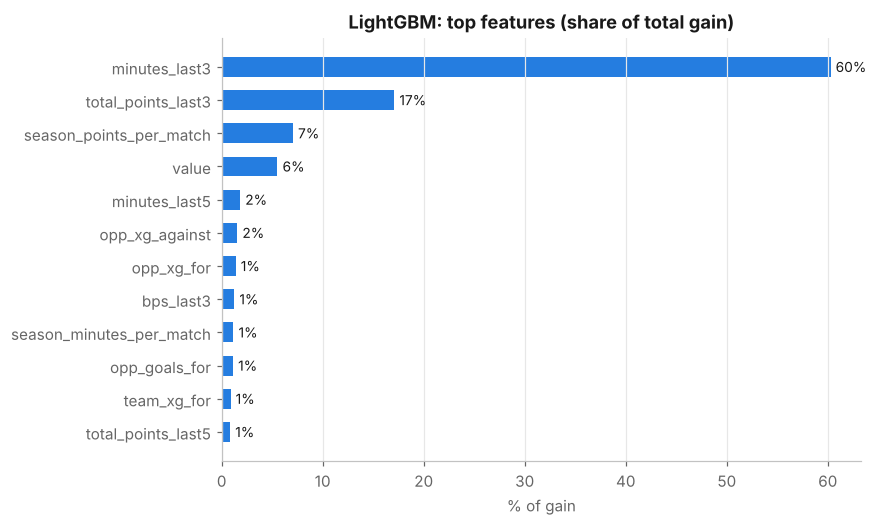

In [5]:
final = models.fit(models.make_lightgbm(**train.LGBM_PARAMS), df[df.total_points.notna()])
imp = pd.Series(final.booster_.feature_importance("gain"), index=features.FEATURES).sort_values().tail(12)
imp = imp / imp.sum() * 100
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(imp.index, imp.values, color=plots.SERIES[0], height=0.6)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
for y, v in enumerate(imp.values):
    ax.annotate(f"{v:.0f}%", (v + 0.5, y), va="center", fontsize=9, color=plots.TEXT)
ax.set(title="LightGBM: top features (share of total gain)", xlabel="% of gain")
fig.savefig(FIG / "feature_importance.png", bbox_inches="tight")

**Minutes over the last 3 matches** dominate, followed by **recent points**, **season points per match** and **price** (a proxy for player quality): the model mostly learns *will he play, and how much does he usually score when he does*. Opponent strength (the opponent's xG for and against) refines that. xG and xA matter less on their own than expected, probably because recent points and price already carry most of the same information.

## 5. Are the predictions calibrated?
Group test predictions into bands and compare with the actual average. A well-calibrated model sits on the diagonal.

,predicted,actual,n
predicted,,,
"(0.0, 0.5]",0.12,0.14,2705
"(0.5, 1.0]",0.79,0.88,581
"(1.0, 2.0]",1.50,1.51,1356
"(2.0, 3.0]",2.47,2.68,1068
"(3.0, 4.0]",3.41,3.76,688
"(4.0, 5.0]",4.36,4.57,126
"(5.0, 6.0]",5.38,4.78,27
"(6.0, 8.0]",6.74,5.09,11


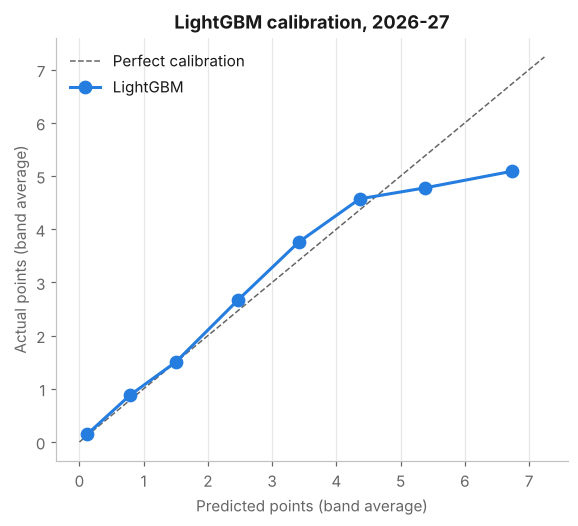

In [6]:
pg = metrics.per_gameweek(test_pred, "lgbm")
bands = pd.cut(pg.predicted, [0, 0.5, 1, 2, 3, 4, 5, 6, 8, 20])
cal = pg.groupby(bands, observed=True).agg(predicted=("predicted", "mean"), actual=("actual", "mean"), n=("actual", "size"))
fig, ax = plt.subplots(figsize=(6, 5))
lim = [0, max(cal.predicted.max(), cal.actual.max()) + 0.5]
ax.plot(lim, lim, color=plots.TEXT_SECONDARY, linewidth=1, linestyle="--", label="Perfect calibration")
ax.plot(cal.predicted, cal.actual, marker="o", markersize=8, color=plots.SERIES[0], label="LightGBM")
ax.legend(loc="upper left")
ax.grid(axis="both")
ax.set(title=f"LightGBM calibration, {train.TEST_SEASON}", xlabel="Predicted points (band average)", ylabel="Actual points (band average)")
fig.savefig(FIG / "calibration.png", bbox_inches="tight")
cal.round(2)

Predictions up to about 5 points match reality closely (slightly cautious). The few predictions above 5 points were too optimistic, but those bands hold only a few dozen player-gameweeks, so they are noisy.

## 6. Conclusions
- **Machine learning helps:** LightGBM's average error is about 12% lower than the last-5 baseline on a season it never saw, and it ranks players better.
- **Ridge ≈ LightGBM** on average error: with noisy targets, a simple linear model gets most of the way. LightGBM is kept because it picks slightly better top players and handles missing early-season history natively.
- **There's a noise ceiling:** a goal is worth 4-6 points and happens rarely, so no pre-match model can be exact. Ranking players well matters more for FPL decisions than exact scores.

**Next improvements:** carry players' previous-season rates into the first weeks, use FPL's injury flags at prediction time, and add set-piece / penalty-taker information.